# Task 6: Categorical Univariate Analysis

**Objective:** Analyze categorical features using frequency distributions, bar charts, pie charts, stacked bar charts, Shannon entropy, and dynamic encoding.

**Input:** `data/processed/womens_clothing_final.csv`  
**Outputs:** `data/processed/womens_clothing_categorical_encoded.csv` and reports in `reports/`.

IDs, URLs, pictures, titles, tags, and free-text descriptions are excluded from categorical encoding.

## 1. Import libraries

In [1]:
import logging
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")


## 2. Load dataset

In [2]:
current_path = Path.cwd()
PROJECT_ROOT = next(
    (p for p in [current_path, *current_path.parents]
     if (p / "data" / "processed" / "womens_clothing_final.csv").exists()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open the main Womens_Clothing_ML_Project folder in VS Code.")
INPUT_PATH = PROJECT_ROOT / "data" / "processed" / "womens_clothing_final.csv"
OUTPUT_PATH = PROJECT_ROOT / "data" / "processed"
REPORT_PATH = PROJECT_ROOT / "reports"
LOG_PATH = PROJECT_ROOT / "logs"
for folder in [OUTPUT_PATH, REPORT_PATH, LOG_PATH]:
    folder.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(INPUT_PATH)
print("Dataset shape:", df.shape)
display(df.head())

logging.basicConfig(
    filename=LOG_PATH / "task_6.log",
    level=logging.INFO,
    format="%(asctime)s - %(levelname)s - %(message)s",
    force=True
)


Dataset shape: (1539, 40)


,title,title_orig,price,retail_price,currency_buyer,units_sold,uses_ad_boosts,rating,rating_count,rating_five_count,...,merchant_name,merchant_info_subtitle,merchant_rating_count,merchant_rating,merchant_id,merchant_has_profile_picture,merchant_profile_picture,product_url,product_picture,product_id
0,2020 Summer Vintage Flamingo Print Pajamas Se...,2020 Summer Vintage Flamingo Print Pajamas Se...,16.00,14.0,EUR,100,False,3.76,54.0,26.0,...,zgrdejia,(568 notes),568.0,4.128521,595097d6a26f6e070cb878d1,False,NaN,https://www.wish.com/c/5e9ae51d43d6a96e303acdb0,https://contestimg.wish.com/api/webimage/5e9ae...,5e9ae51d43d6a96e303acdb0
1,SSHOUSE Summer Casual Sleeveless Soirée Party ...,Women's Casual Summer Sleeveless Sexy Mini Dress,8.00,22.0,EUR,12350,True,3.45,2143.5,1058.0,...,sarahouse,"83 % avis positifs (17,752 notes)",17752.0,3.899673,56458aa03a698c35c9050988,False,NaN,https://www.wish.com/c/58940d436a0d3d5da4e95a38,https://contestimg.wish.com/api/webimage/58940...,58940d436a0d3d5da4e95a38
2,2020 Nouvelle Arrivée Femmes Printemps et Été ...,2020 New Arrival Women Spring and Summer Beach...,8.00,43.0,EUR,100,False,3.57,14.0,5.0,...,hxt520,86 % avis positifs (295 notes),295.0,3.989831,5d464a1ffdf7bc44ee933c65,False,NaN,https://www.wish.com/c/5ea10e2c617580260d55310a,https://contestimg.wish.com/api/webimage/5ea10...,5ea10e2c617580260d55310a
3,Hot Summer Cool T-shirt pour les femmes Mode T...,Hot Summer Cool T Shirt for Women Fashion Tops...,8.00,8.0,EUR,5000,True,4.03,579.0,295.0,...,allenfan,"(23,832 notes)",23832.0,4.020435,58cfdefdacb37b556efdff7c,False,NaN,https://www.wish.com/c/5cedf17ad1d44c52c59e4aca,https://contestimg.wish.com/api/webimage/5cedf...,5cedf17ad1d44c52c59e4aca
4,Femmes Shorts d'été à lacets taille élastique ...,Women Summer Shorts Lace Up Elastic Waistband ...,2.72,3.0,EUR,100,True,3.10,20.0,6.0,...,happyhorses,"85 % avis positifs (14,482 notes)",14482.0,4.001588,5ab3b592c3911a095ad5dadb,False,NaN,https://www.wish.com/c/5ebf5819ebac372b070b0e70,https://contestimg.wish.com/api/webimage/5ebf5...,5ebf5819ebac372b070b0e70


## 3. Identify categorical columns dynamically

In [3]:
excluded_columns = [
    "title", "title_orig", "tags", "merchant_title",
    "merchant_name", "merchant_info_subtitle",
    "merchant_id", "product_id", "product_url",
    "product_picture", "merchant_profile_picture"
]
categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()
categorical_columns = [c for c in categorical_columns if c not in excluded_columns]

binary_columns = [
    c for c in df.select_dtypes(include=np.number).columns
    if df[c].nunique(dropna=True) <= 2
]
categorical_columns = list(dict.fromkeys(categorical_columns + binary_columns))

print("Categorical columns:", len(categorical_columns))
print(categorical_columns)
if not categorical_columns:
    raise ValueError("No categorical columns found.")


Categorical columns: 14
['currency_buyer', 'uses_ad_boosts', 'badge_local_product', 'badge_product_quality', 'badge_fast_shipping', 'product_color', 'product_variation_size_id', 'shipping_option_name', 'shipping_is_express', 'urgency_text', 'origin_country', 'merchant_has_profile_picture', 'badges_count', 'inventory_total']


## 4. Calculate frequency distributions

In [4]:
def calculate_frequency(data, columns):
    frequency_reports = {}
    for col in columns:
        frequency = (
            data[col].fillna("Unknown").astype(str)
            .value_counts()
            .rename_axis("Category")
            .reset_index(name="Count")
        )
        frequency["Percentage"] = frequency["Count"] / frequency["Count"].sum() * 100
        frequency_reports[col] = frequency
        print(f"Frequency distribution: {col}")
        display(frequency.head(10))
    return frequency_reports

frequency_reports = calculate_frequency(df, categorical_columns)


Frequency distribution: currency_buyer


,Category,Count,Percentage
0,EUR,1539,100.0


Frequency distribution: uses_ad_boosts


,Category,Count,Percentage
0,False,868,56.40026
1,True,671,43.59974


Frequency distribution: badge_local_product


,Category,Count,Percentage
0,False,1510,98.11566
1,True,29,1.88434


... (18 outputs left out)

Frequency distribution: badges_count


,Category,Count,Percentage
0,0,1539,100.0


Frequency distribution: inventory_total


,Category,Count,Percentage
0,50,1539,100.0


## 5. Custom frequency bar chart

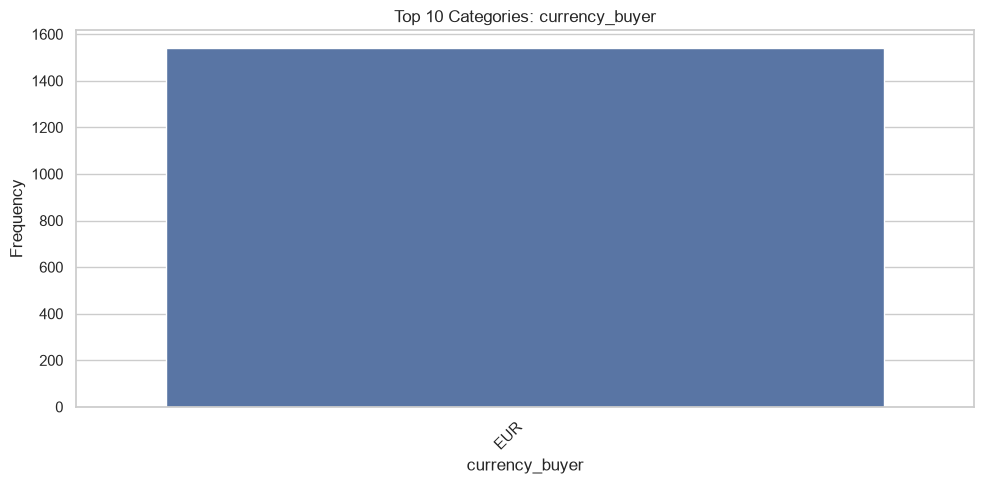

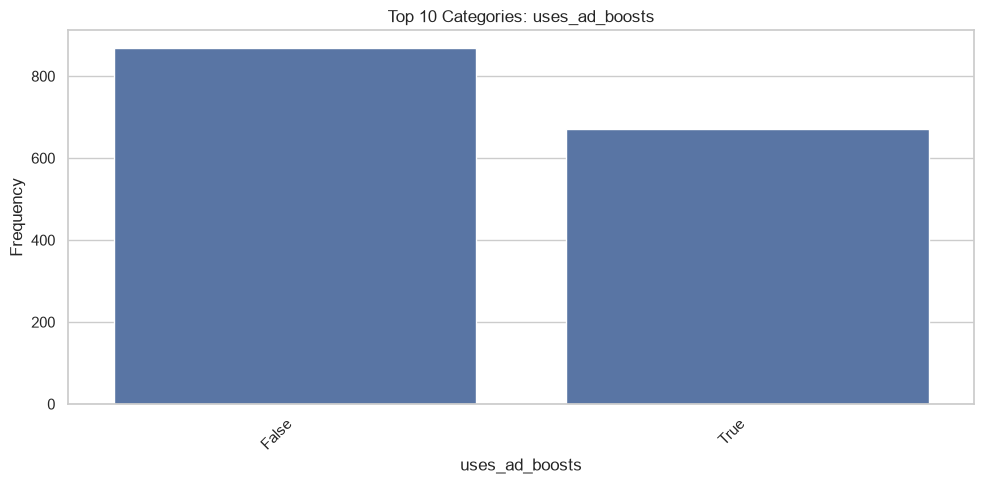

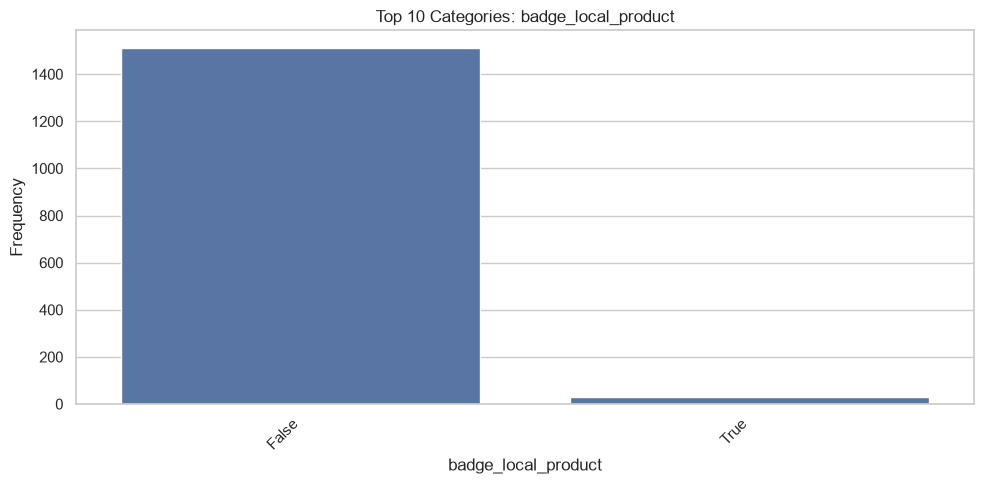

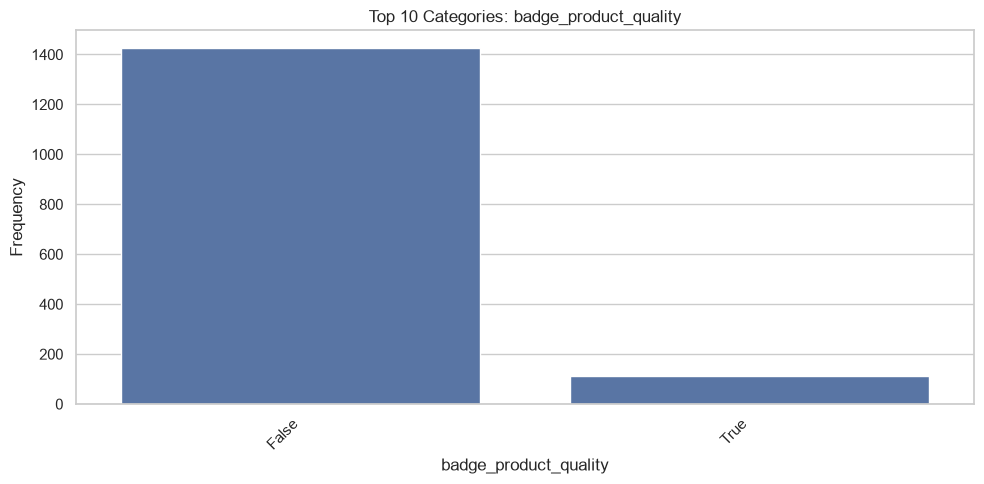

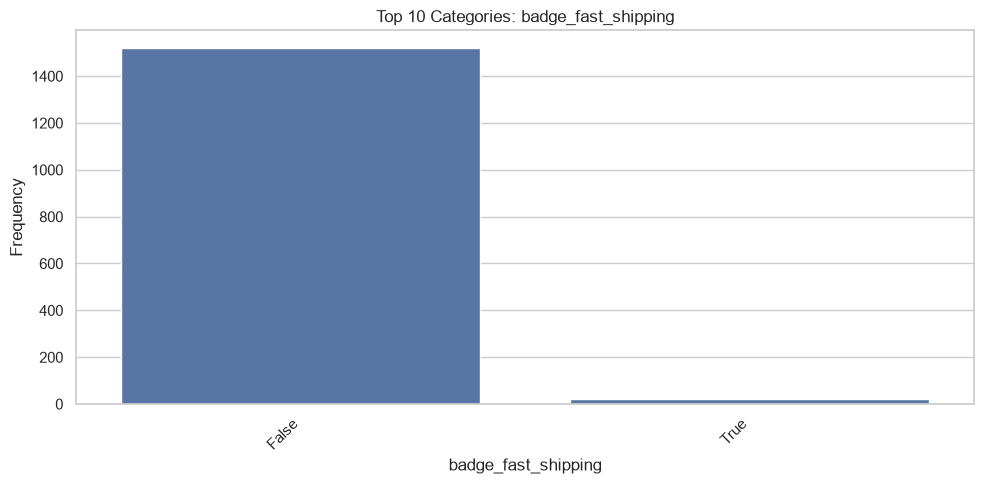

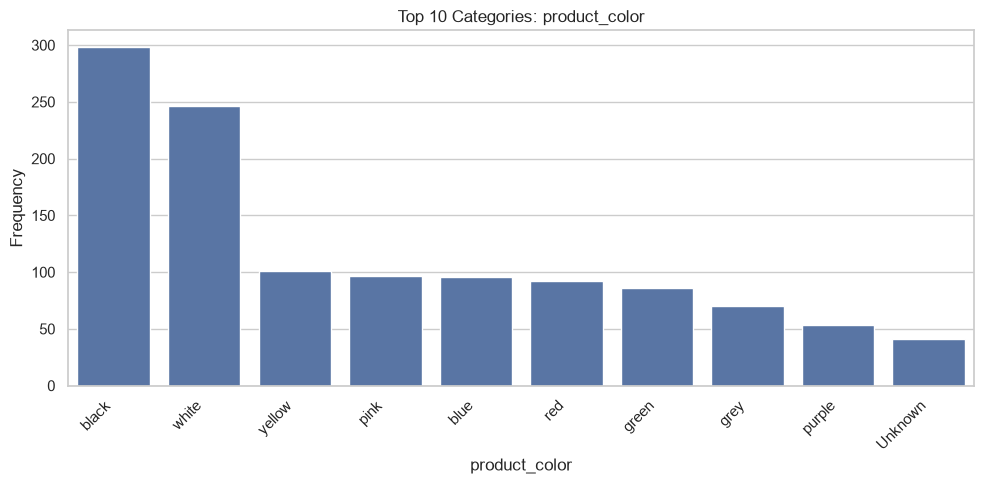

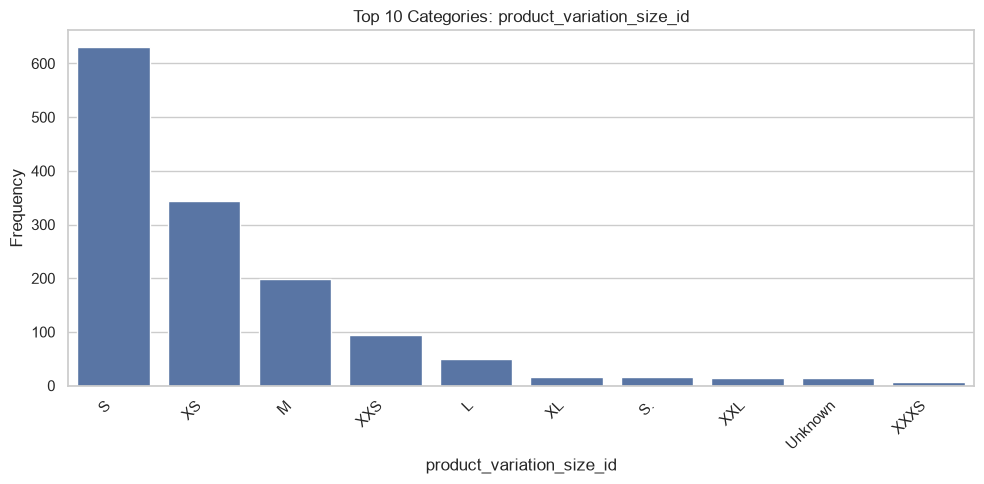

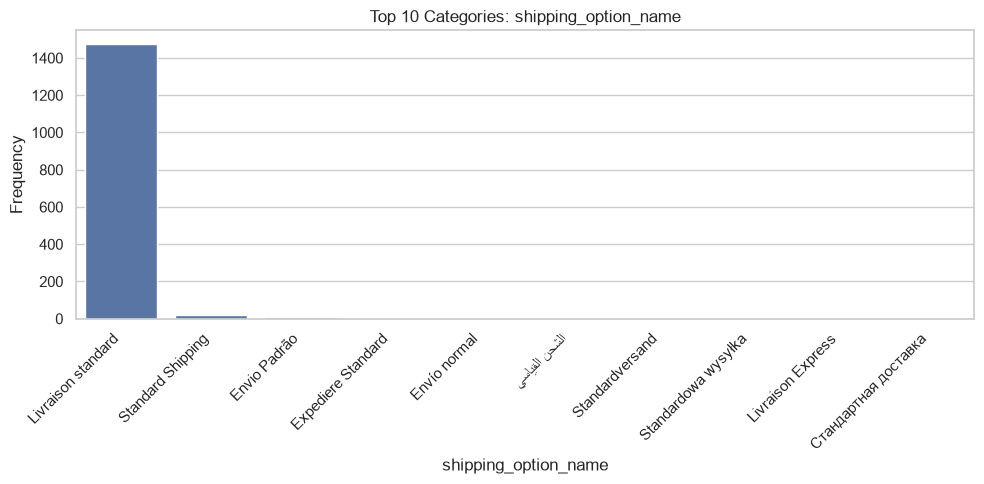

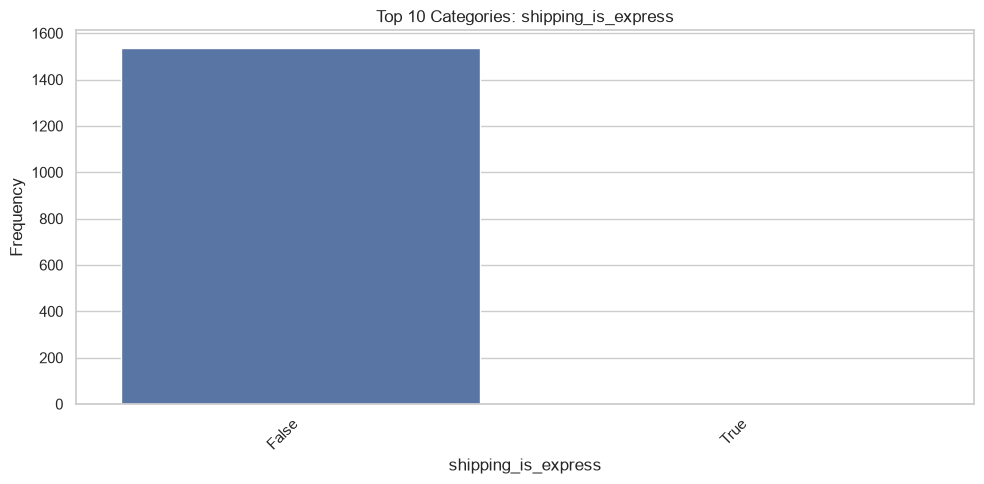

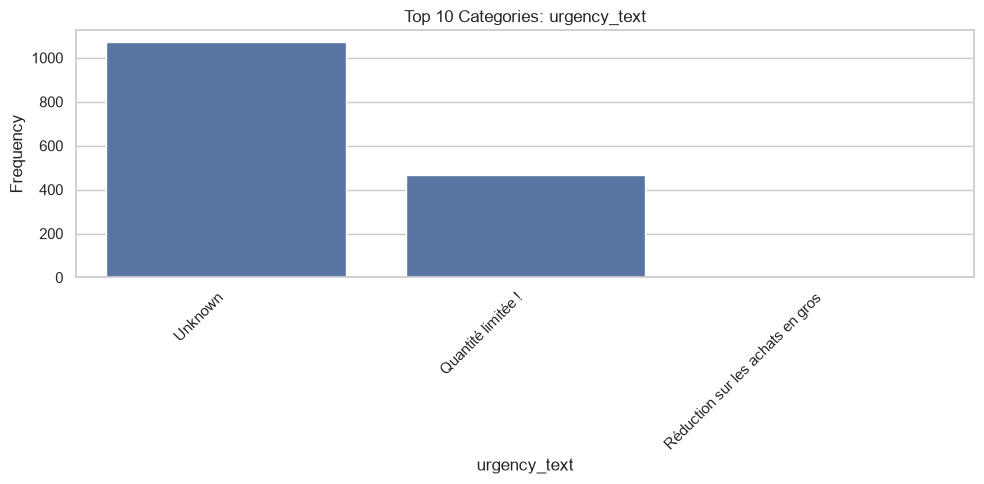

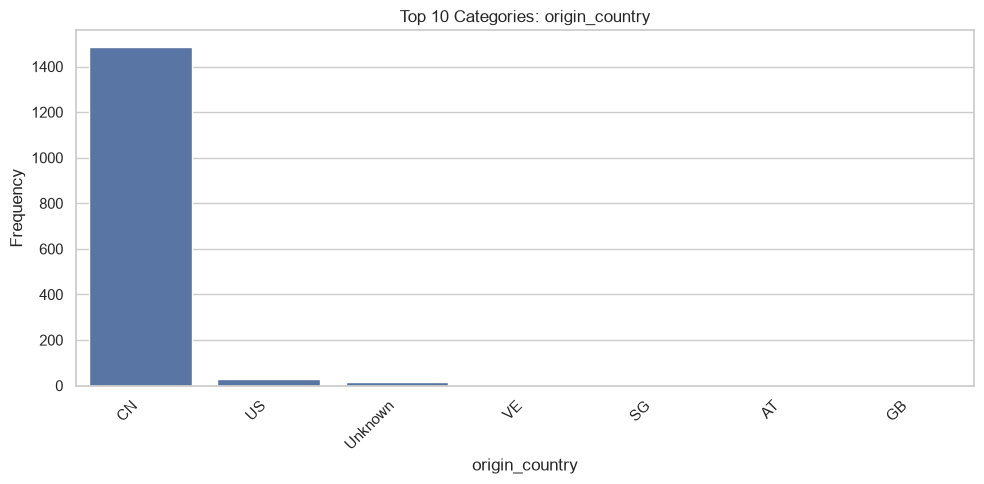

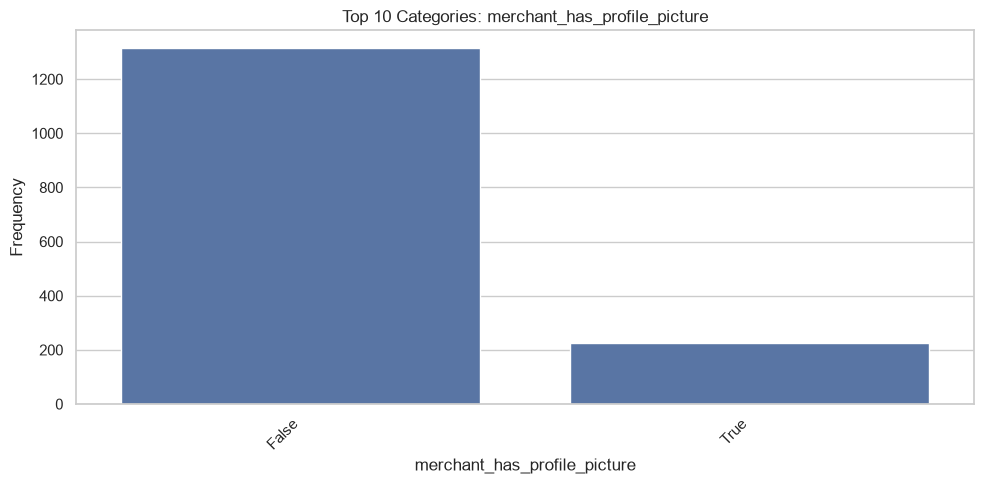

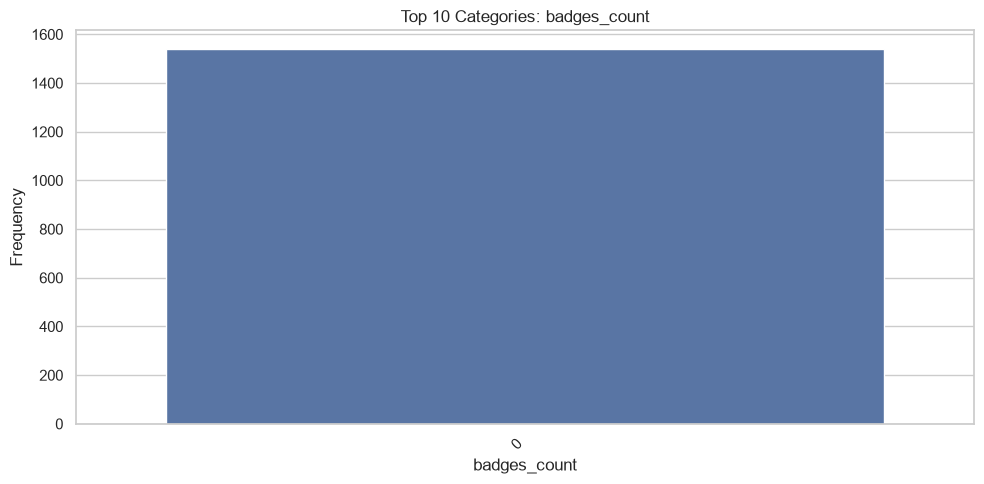

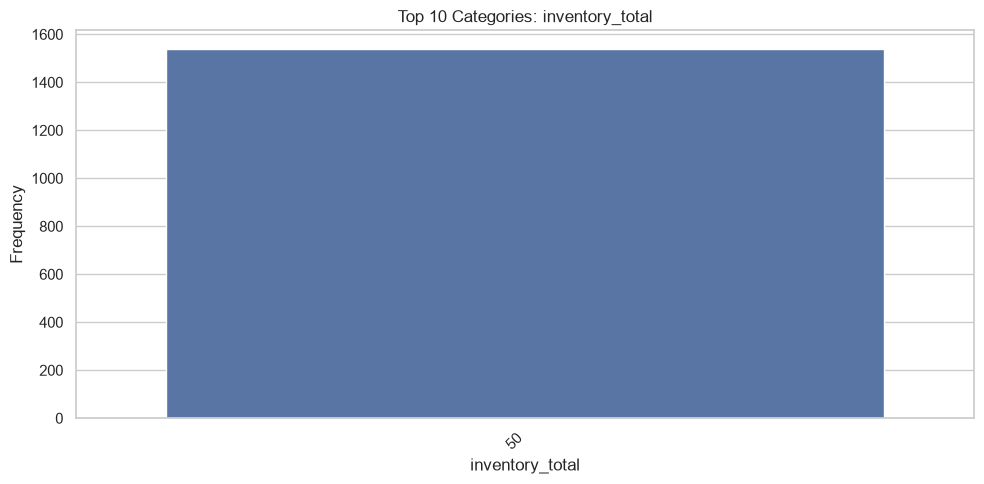

In [5]:
def plot_frequency(data, column, top_n=10):
    values = (
        data[column].fillna("Unknown").astype(str)
        .value_counts().head(top_n)
        .rename_axis("Category")
        .reset_index(name="Count")
    )
    plt.figure(figsize=(10, 5))
    sns.barplot(data=values, x="Category", y="Count")
    plt.title(f"Top {top_n} Categories: {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

for col in categorical_columns:
    plot_frequency(df, col)


## 6. Custom pie chart

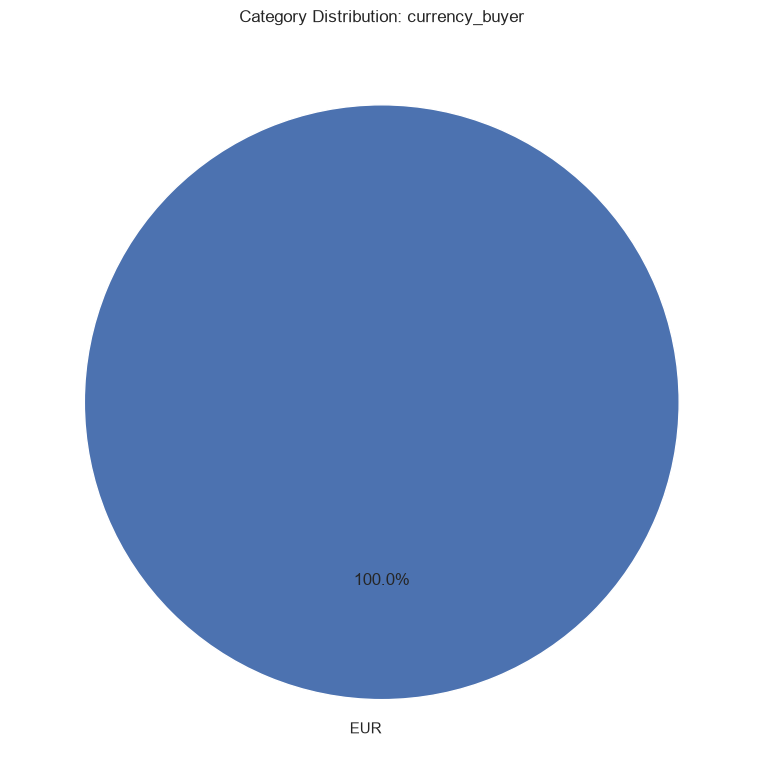

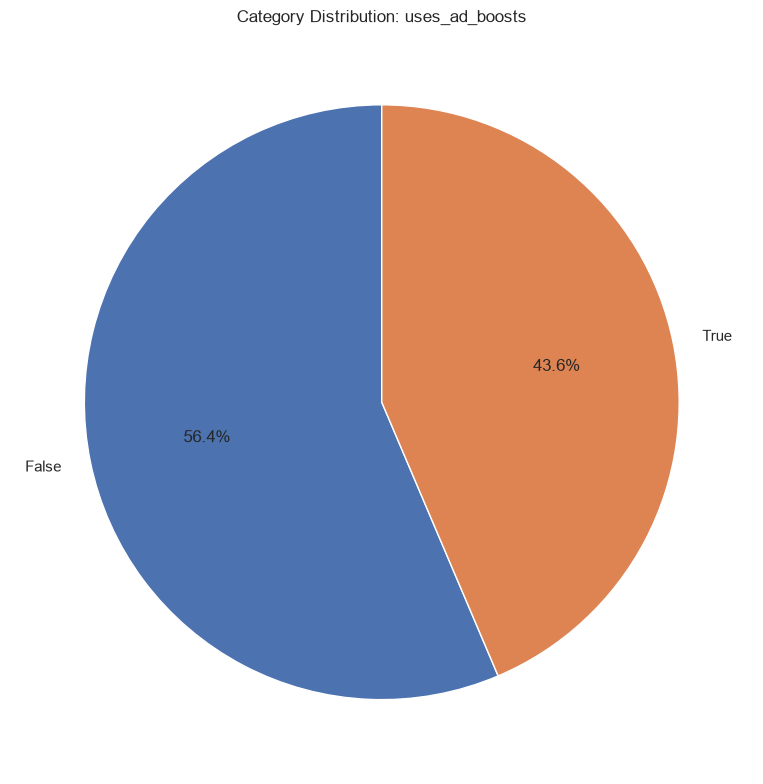

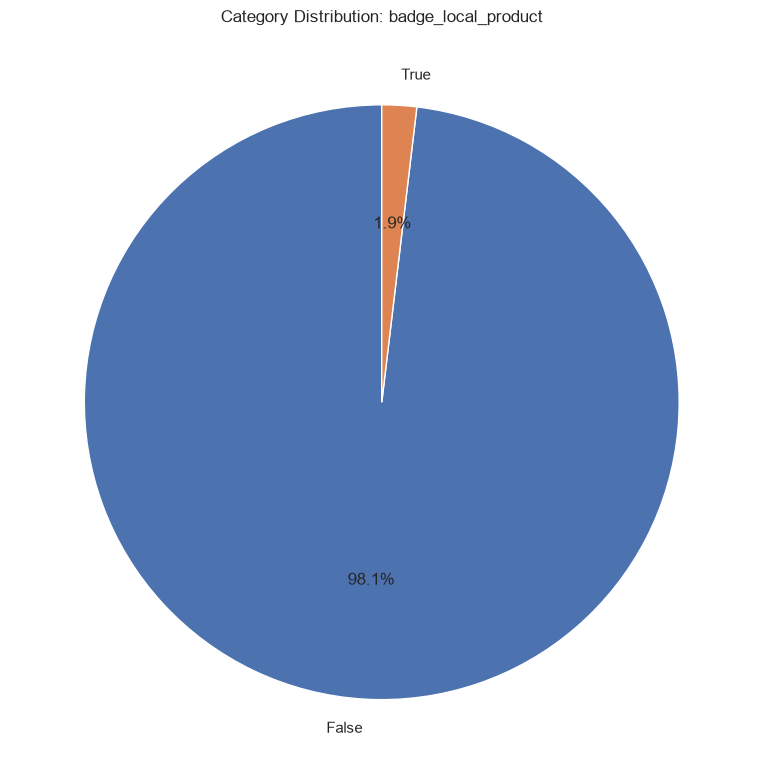

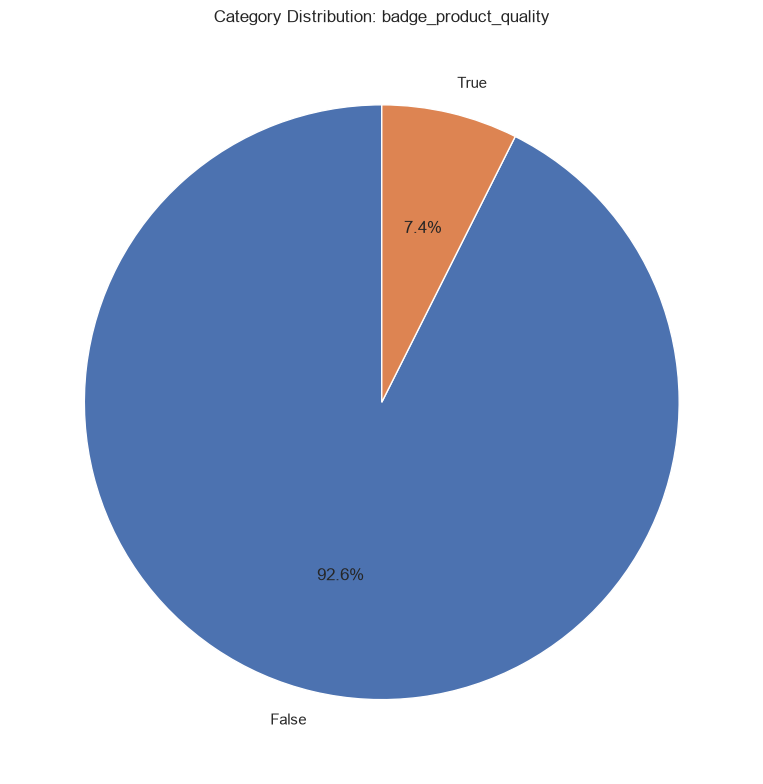

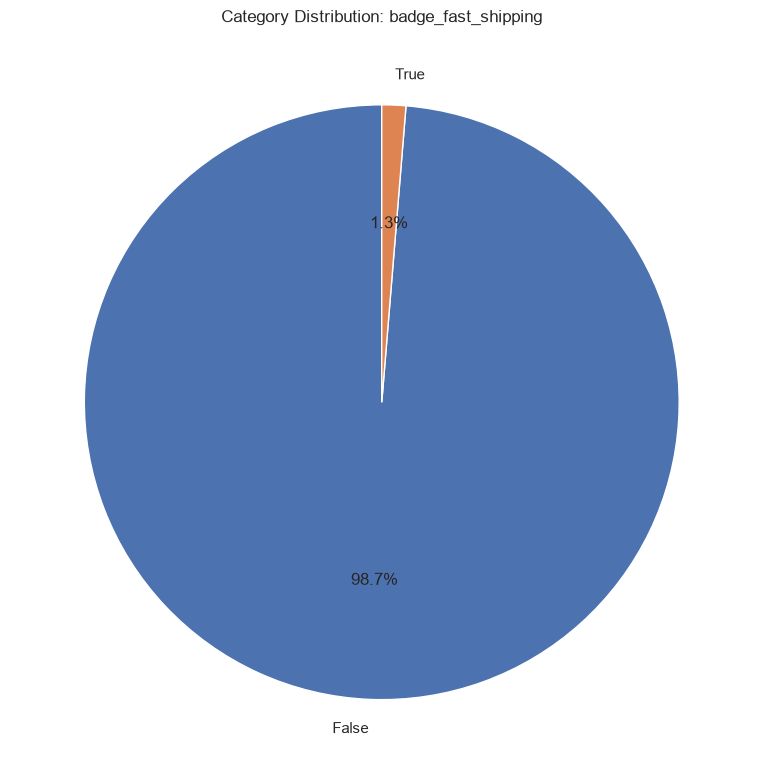

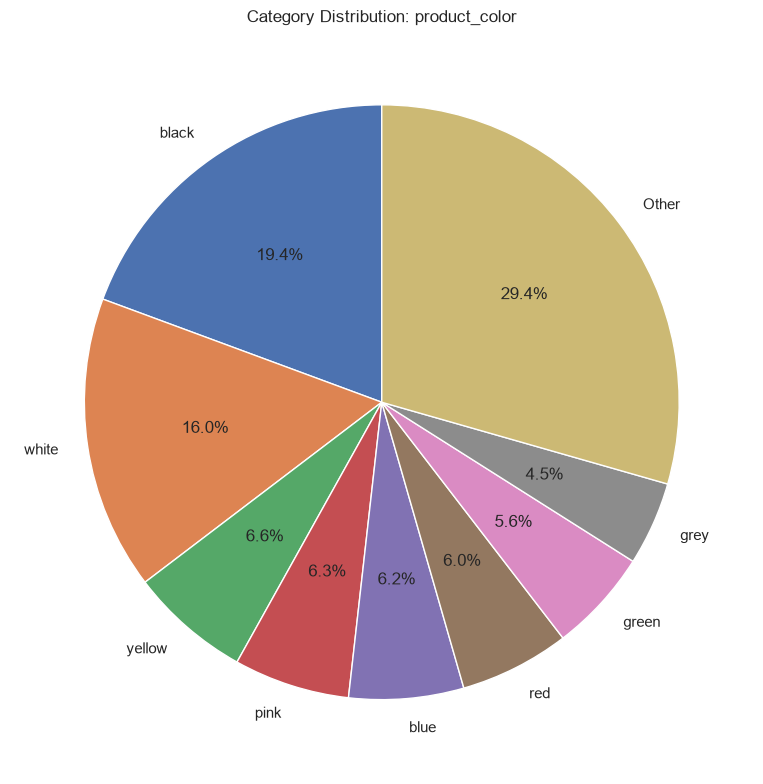

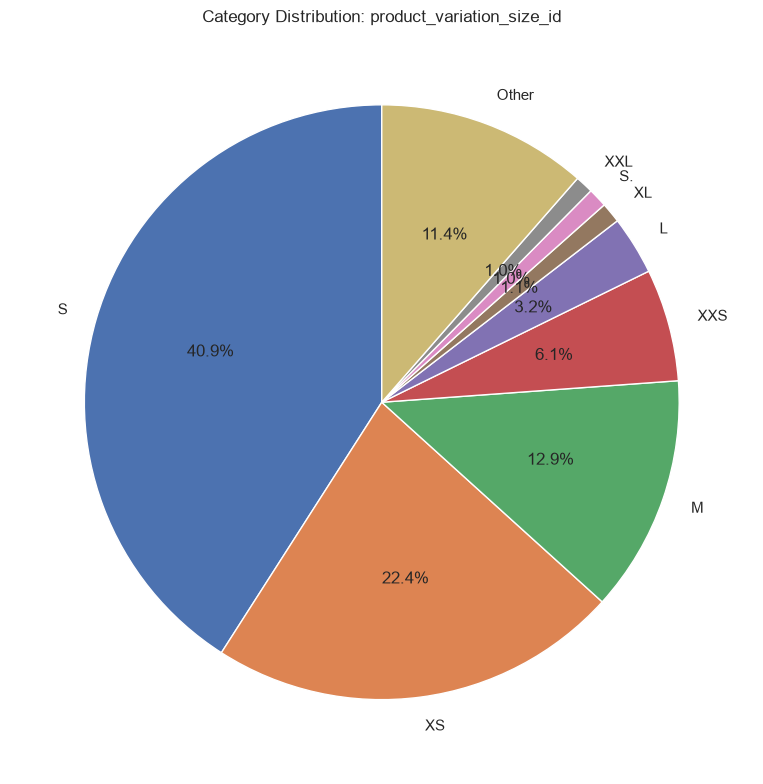

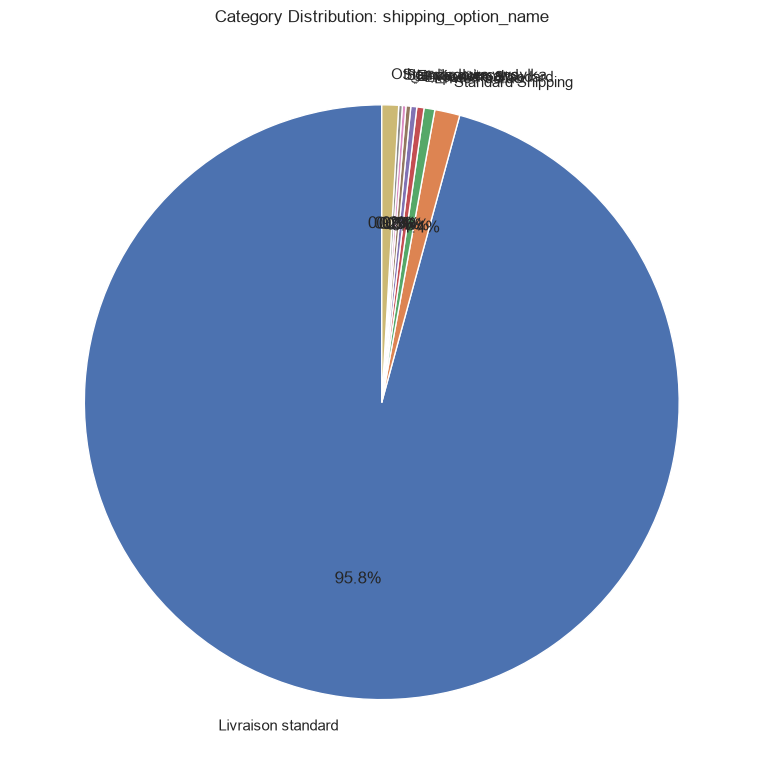

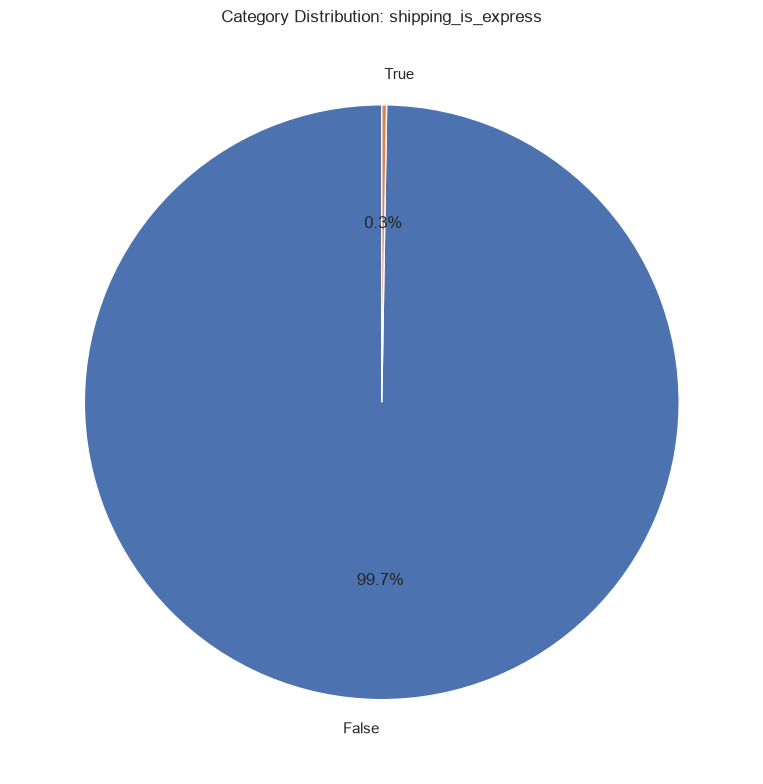

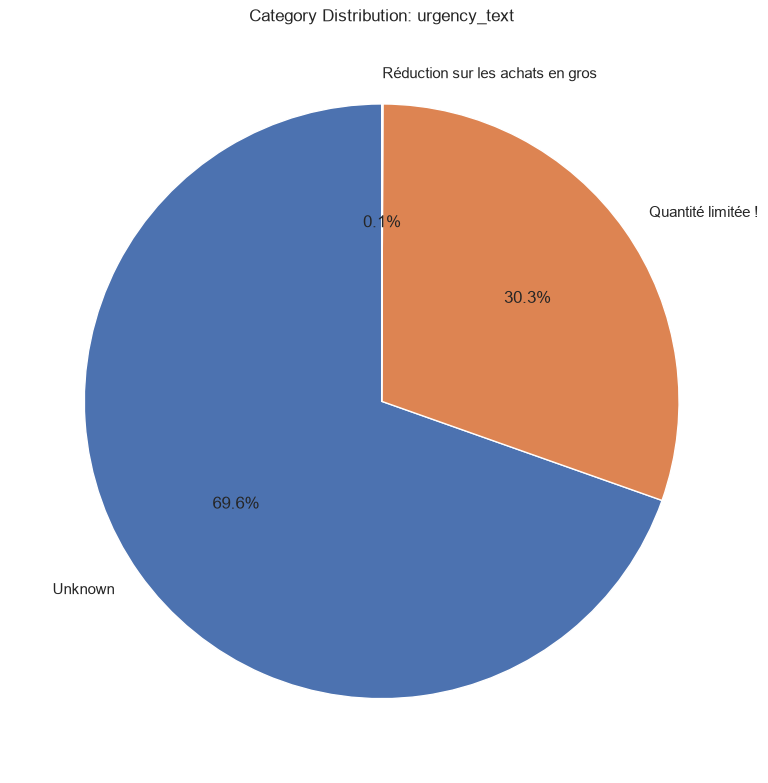

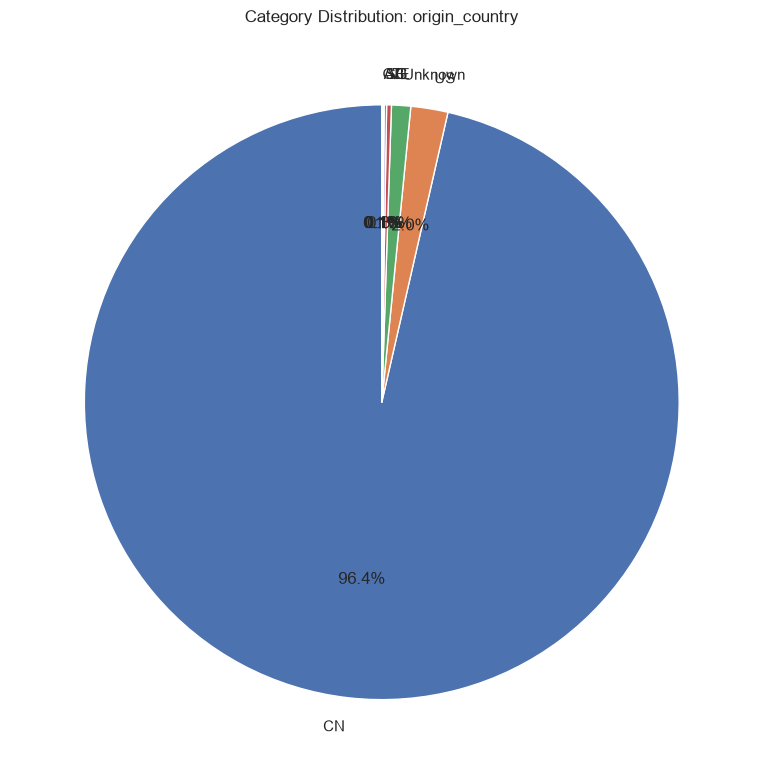

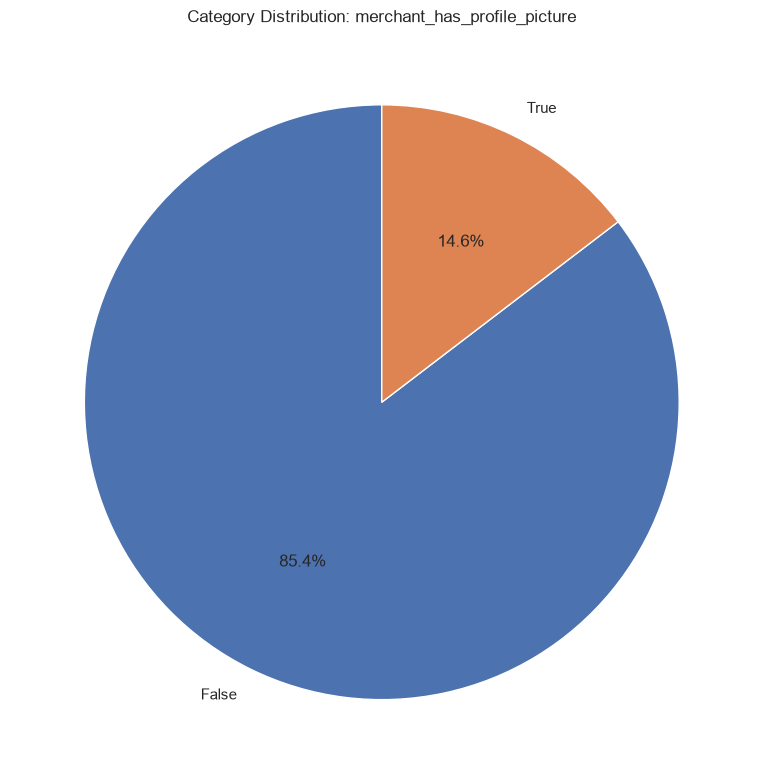

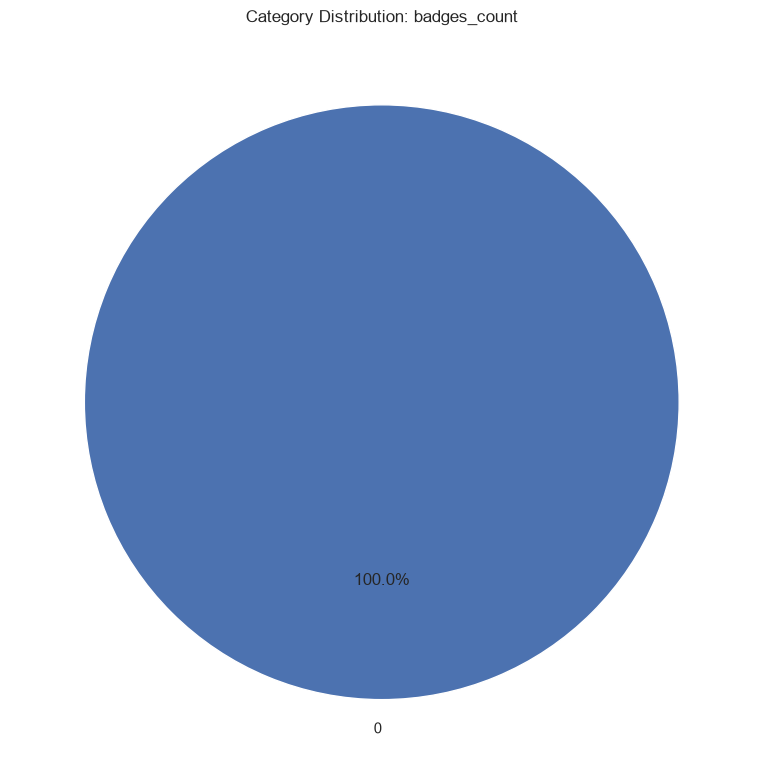

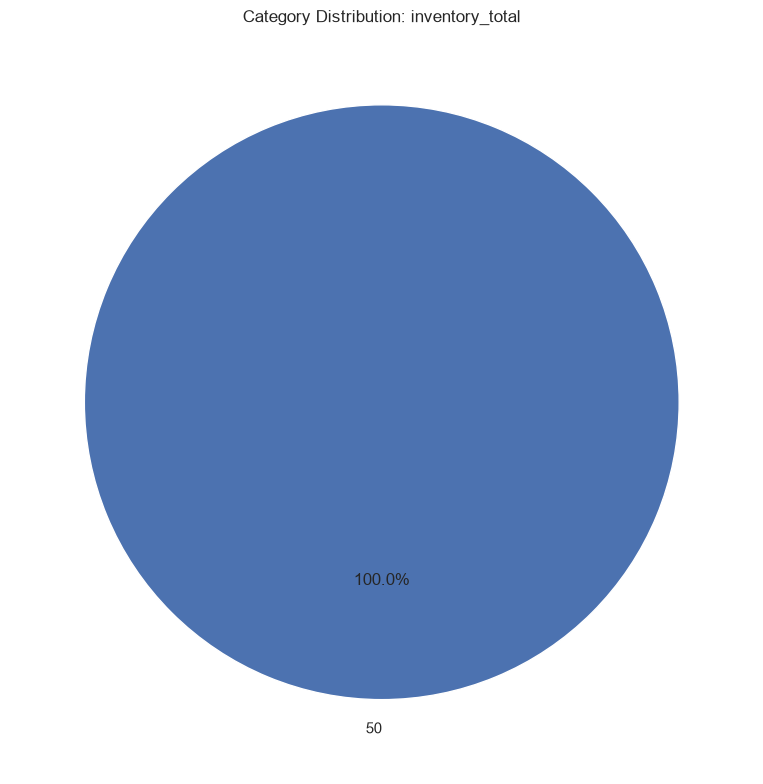

In [6]:
def plot_pie_chart(data, column, top_n=8):
    values = data[column].fillna("Unknown").astype(str).value_counts()
    top_values = values.head(top_n).copy()
    if len(values) > top_n:
        top_values.loc["Other"] = values.iloc[top_n:].sum()
    if top_values.empty:
        print(f"No categories available for {column}")
        return
    plt.figure(figsize=(8, 8))
    plt.pie(top_values.values, labels=top_values.index, autopct="%1.1f%%", startangle=90)
    plt.title(f"Category Distribution: {column}")
    plt.tight_layout()
    plt.show()

for col in categorical_columns:
    plot_pie_chart(df, col)


## 7. Stacked bar charts

A suitable low-cardinality grouping column is selected automatically. Less frequent categories are combined into `Other` to keep charts readable.

Grouping column: shipping_is_express


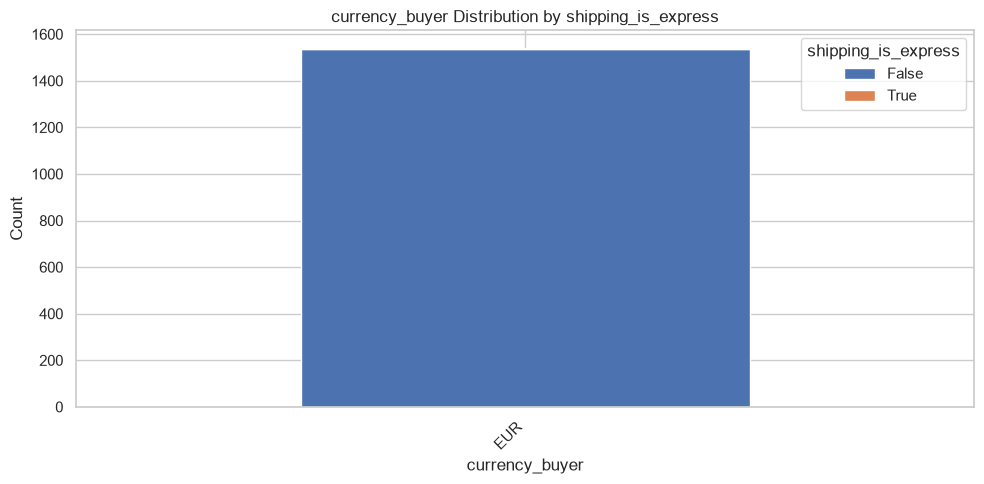

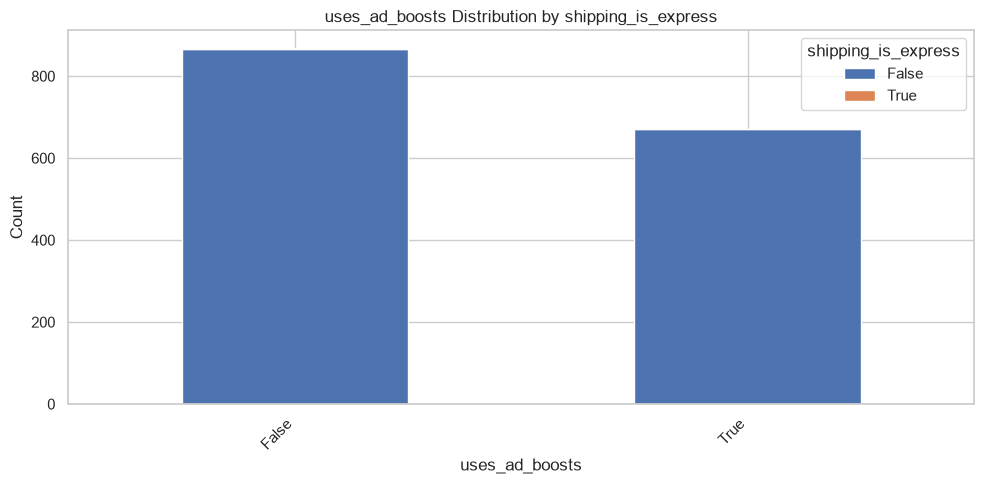

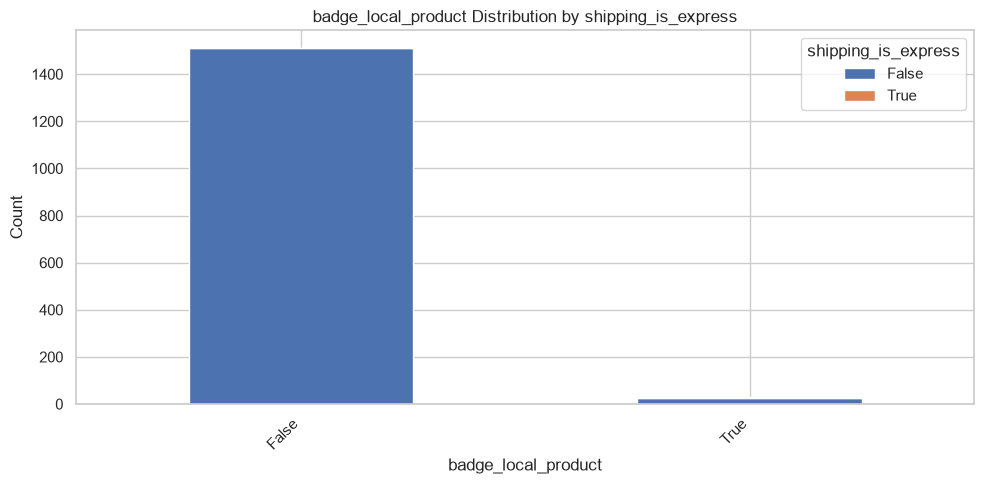

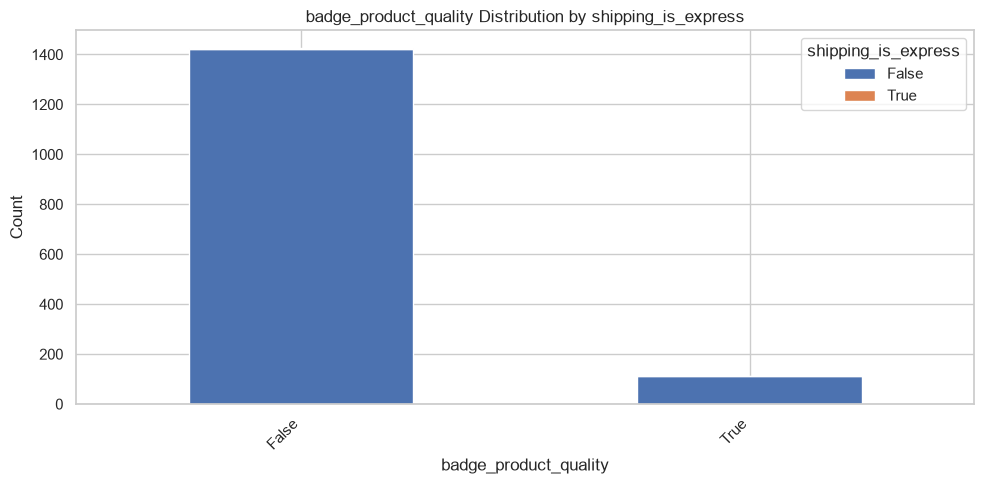

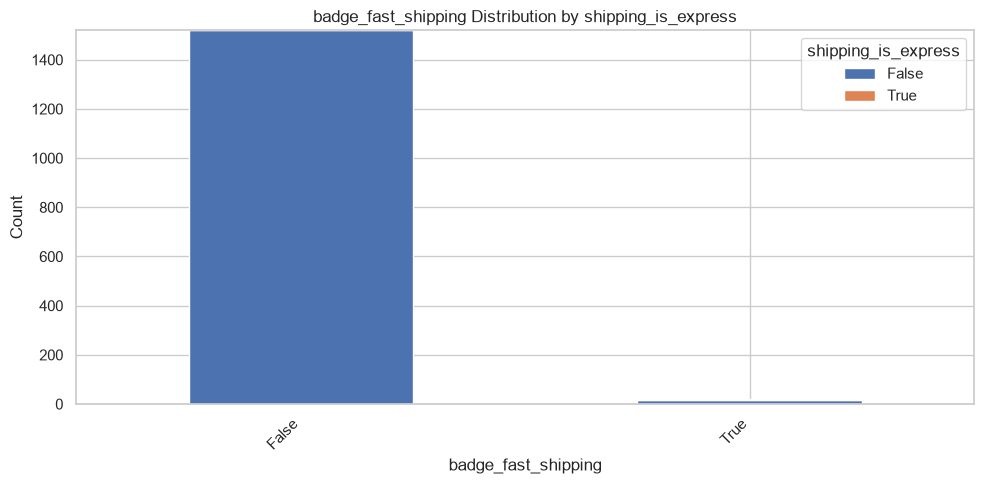

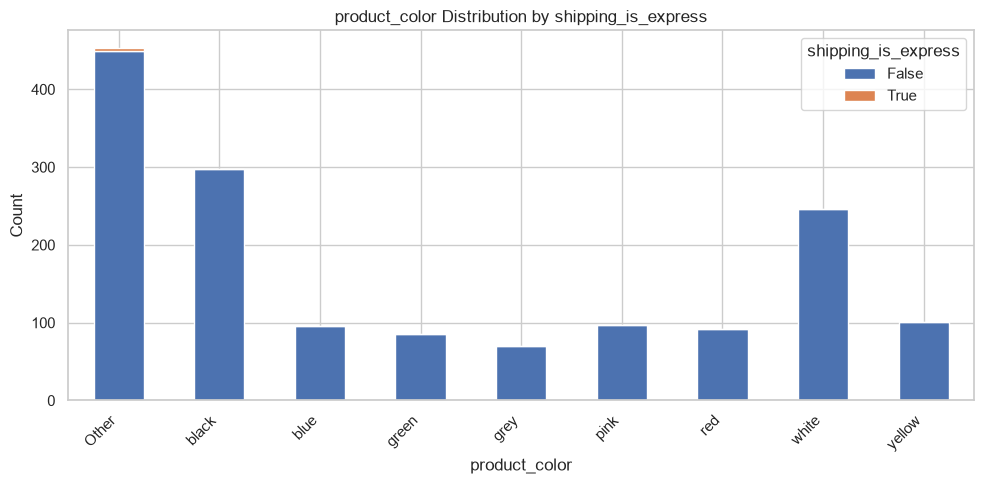

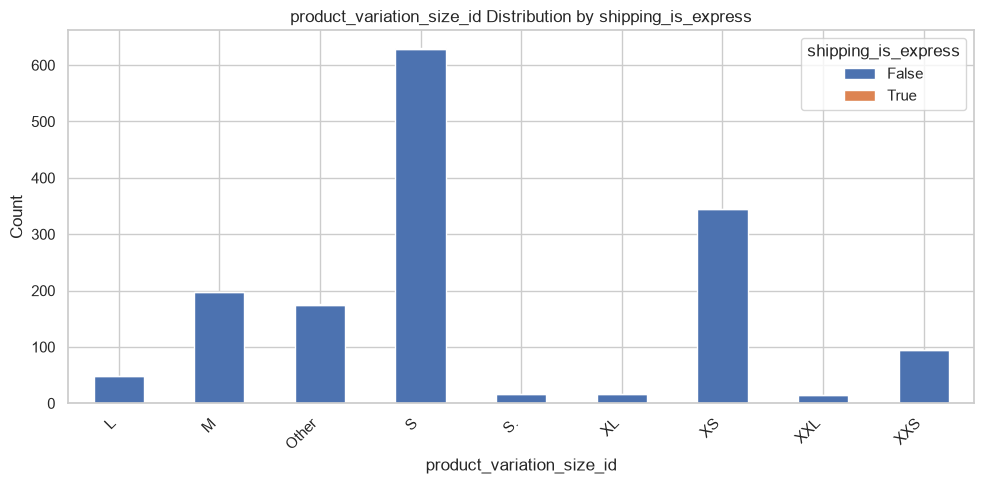

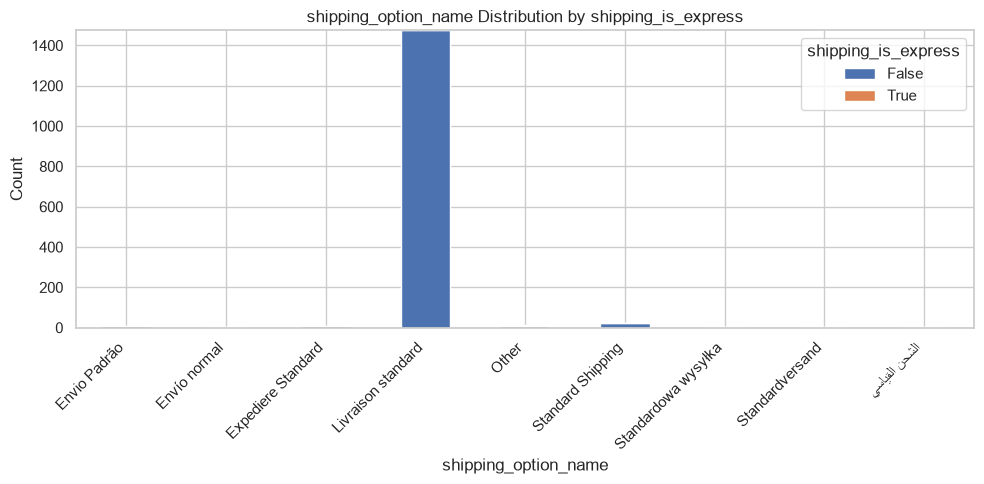

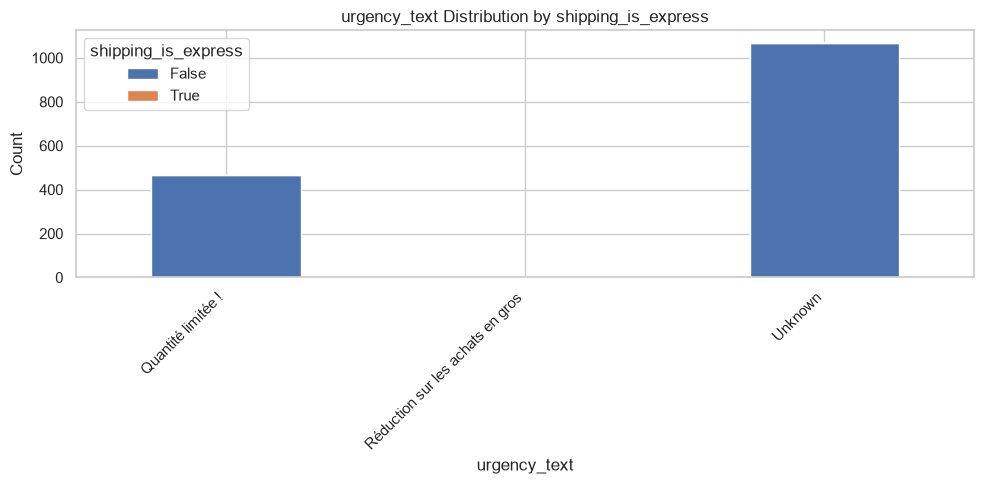

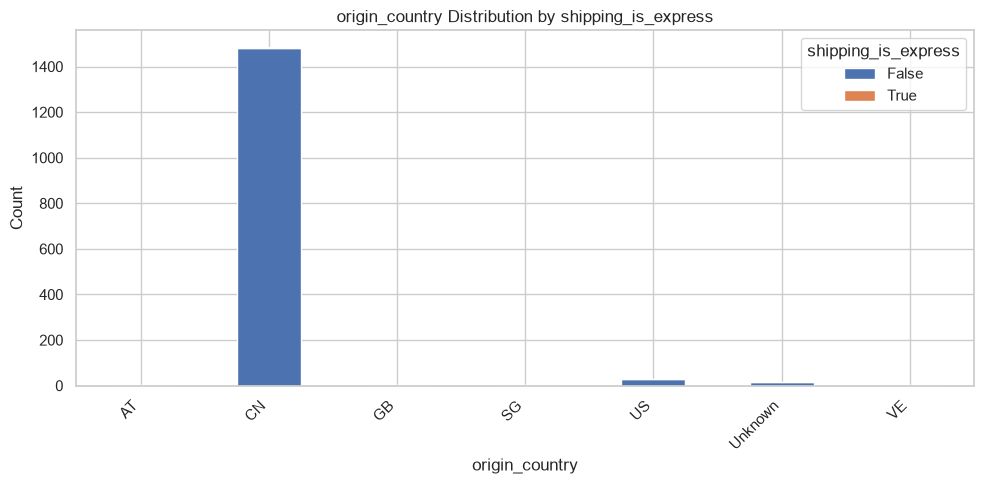

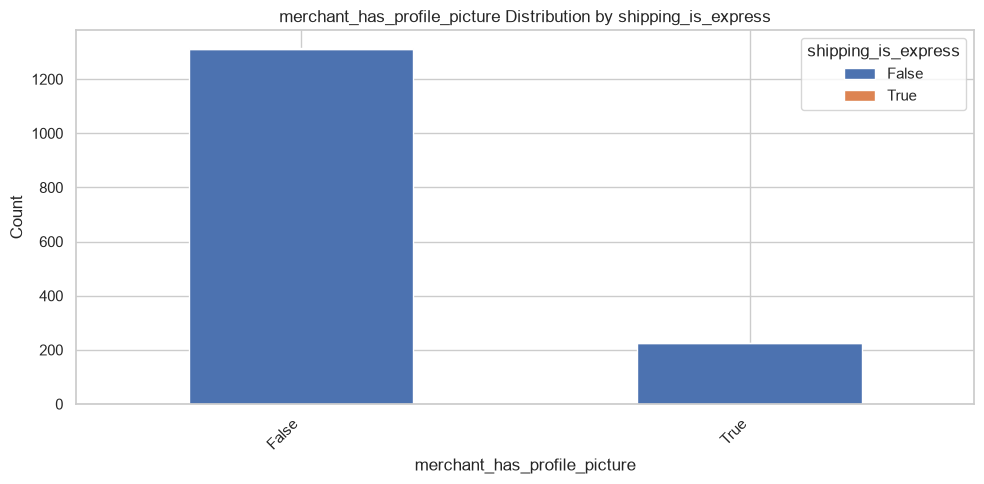

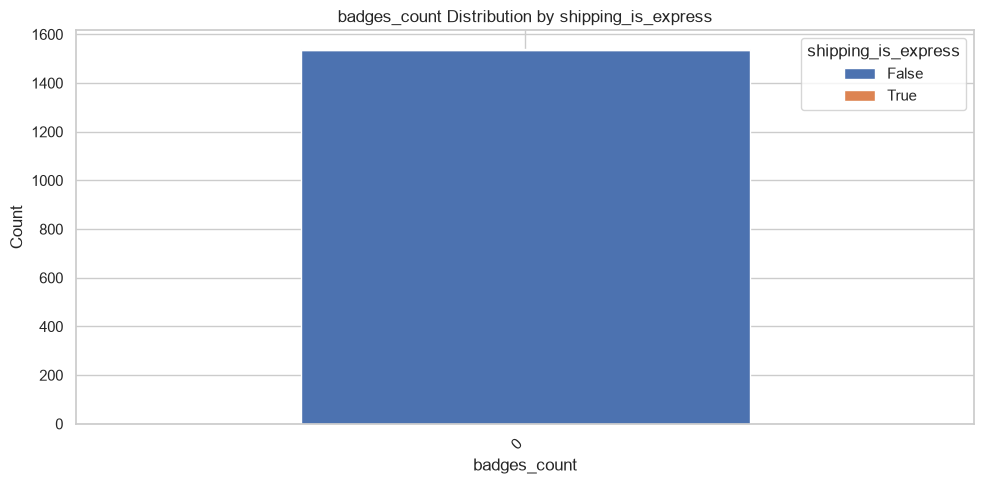

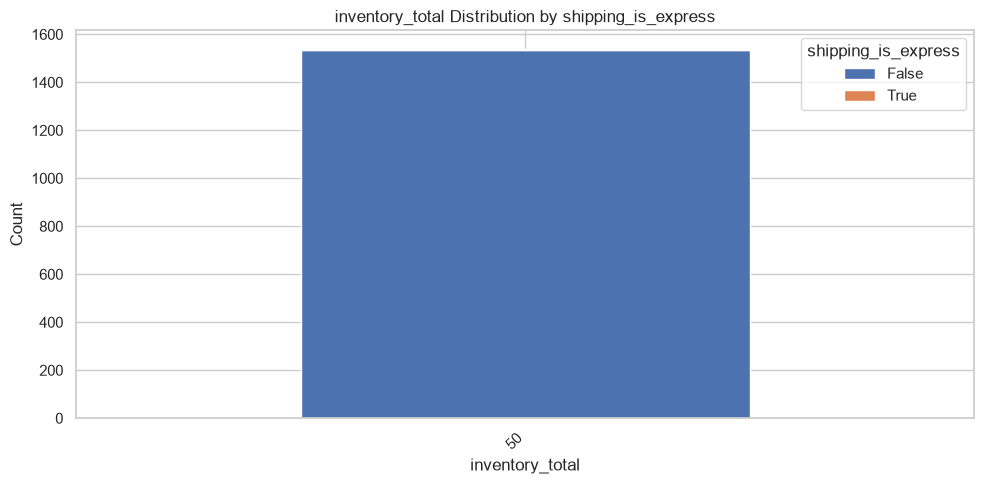

In [7]:
def plot_stacked_bar(data, category_column, group_column, top_n=8):
    plot_data = data[[category_column, group_column]].copy()
    plot_data[category_column] = plot_data[category_column].fillna("Unknown").astype(str)
    plot_data[group_column] = plot_data[group_column].fillna("Unknown").astype(str)

    top_categories = plot_data[category_column].value_counts().head(top_n).index
    plot_data[category_column] = plot_data[category_column].where(
        plot_data[category_column].isin(top_categories), "Other"
    )
    cross_tab = pd.crosstab(plot_data[category_column], plot_data[group_column])
    cross_tab.plot(kind="bar", stacked=True, figsize=(10, 5))
    plt.title(f"{category_column} Distribution by {group_column}")
    plt.xlabel(category_column)
    plt.ylabel("Count")
    plt.xticks(rotation=45, ha="right")
    plt.legend(title=group_column)
    plt.tight_layout()
    plt.show()

preferred_groups = ["shipping_is_express", "badge_local_product"]
group_column = next((c for c in preferred_groups if c in df.columns), None)
if group_column is None:
    candidates = [c for c in categorical_columns if df[c].nunique(dropna=True) <= 5]
    group_column = candidates[0] if candidates else None

if group_column:
    print("Grouping column:", group_column)
    for col in categorical_columns:
        if col != group_column:
            plot_stacked_bar(df, col, group_column)
else:
    print("No suitable low-cardinality grouping column found.")


## 8. Calculate Shannon entropy and normalized entropy

In [8]:
def calculate_entropy(data, columns):
    results = []
    for col in columns:
        values = data[col].fillna("Unknown").astype(str)
        probabilities = values.value_counts(normalize=True)
        entropy = -np.sum(probabilities * np.log2(probabilities))
        unique_categories = values.nunique()
        maximum_entropy = np.log2(unique_categories) if unique_categories > 1 else 0
        normalized_entropy = entropy / maximum_entropy if maximum_entropy > 0 else 0
        results.append({
            "Feature": col,
            "Unique_Categories": unique_categories,
            "Entropy": entropy,
            "Normalized_Entropy": normalized_entropy
        })
    return pd.DataFrame(results)

entropy_report = calculate_entropy(df, categorical_columns)
entropy_report = entropy_report.sort_values("Entropy", ascending=False).reset_index(drop=True)
display(entropy_report)


,Feature,Unique_Categories,Entropy,Normalized_Entropy
0,product_color,102,4.404549,0.660112
1,product_variation_size_id,107,3.073241,0.455871
2,uses_ad_boosts,2,0.988148,0.988148
3,urgency_text,3,0.892938,0.563381
4,merchant_has_profile_picture,2,0.600246,0.600246
5,shipping_option_name,15,0.389256,0.099633
6,badge_product_quality,2,0.380947,0.380947
7,origin_country,7,0.281131,0.100141
8,badge_local_product,2,0.134896,0.134896
9,badge_fast_shipping,2,0.100054,0.100054


## 9. Visualize normalized entropy

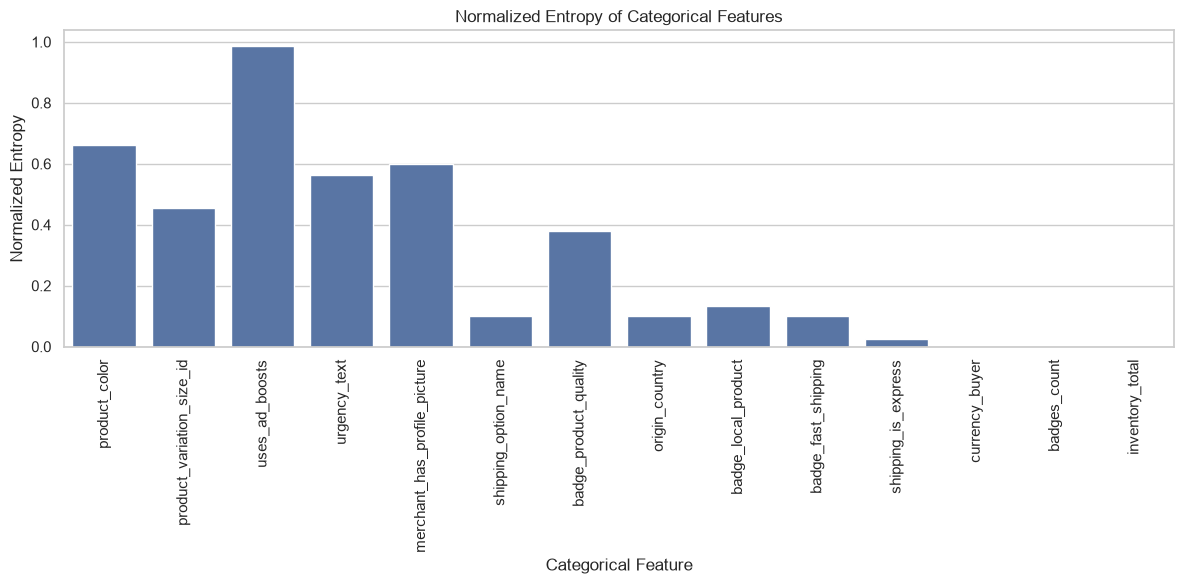

In [9]:
plt.figure(figsize=(12, 6))
sns.barplot(data=entropy_report, x="Feature", y="Normalized_Entropy")
plt.title("Normalized Entropy of Categorical Features")
plt.xlabel("Categorical Feature")
plt.ylabel("Normalized Entropy")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


## 10. Dynamically encode categorical features

In [10]:
CARDINALITY_THRESHOLD = 10
encoded_df = df.copy()
encoding_summary = []

for col in categorical_columns:
    values = df[col].fillna("Unknown").astype(str)
    unique_count = values.nunique()

    if unique_count <= CARDINALITY_THRESHOLD:
        dummies = pd.get_dummies(values, prefix=col, dtype=int)
        encoded_df = pd.concat([encoded_df, dummies], axis=1)
        method = "One-Hot Encoding"
    else:
        frequency_map = values.value_counts(normalize=True)
        encoded_df[f"{col}_frequency_encoded"] = values.map(frequency_map)
        method = "Frequency Encoding"

    encoding_summary.append({
        "Feature": col,
        "Unique_Categories": unique_count,
        "Encoding_Method": method
    })
    logging.info("%s encoded using %s", col, method)

encoding_report = pd.DataFrame(encoding_summary)
display(encoding_report)


,Feature,Unique_Categories,Encoding_Method
0,currency_buyer,1,One-Hot Encoding
1,uses_ad_boosts,2,One-Hot Encoding
2,badge_local_product,2,One-Hot Encoding
3,badge_product_quality,2,One-Hot Encoding
4,badge_fast_shipping,2,One-Hot Encoding
5,product_color,102,Frequency Encoding
6,product_variation_size_id,107,Frequency Encoding
7,shipping_option_name,15,Frequency Encoding
8,shipping_is_express,2,One-Hot Encoding
9,urgency_text,3,One-Hot Encoding


## 11. Save reports and encoded dataset

In [11]:
entropy_report.to_csv(REPORT_PATH / "task_6_categorical_analysis.csv", index=False)
encoding_report.to_csv(REPORT_PATH / "task_6_encoding_summary.csv", index=False)

OUTPUT_FILE = OUTPUT_PATH / "womens_clothing_categorical_encoded.csv"
encoded_df.to_csv(OUTPUT_FILE, index=False)

logging.info("Categorical univariate analysis completed.")
logging.info("Encoded dataset saved to %s", OUTPUT_FILE)
print("Encoded dataset shape:", encoded_df.shape)
print("Saved:", OUTPUT_FILE)


Encoded dataset shape: (1539, 68)
Saved: d:\OneDrive\Desktop\Brainybeams\Womens_Clothing_ML_Project\data\processed\womens_clothing_categorical_encoded.csv


## 12. Final summary

In [12]:
print("TASK 6 COMPLETED")
print("Categorical columns analyzed:", len(categorical_columns))
print("Low-cardinality encoding: One-Hot Encoding")
print("High-cardinality encoding: Frequency Encoding")
print("Encoding threshold:", CARDINALITY_THRESHOLD)
print("Reports:", REPORT_PATH)
print("Encoded dataset:", OUTPUT_FILE)


TASK 6 COMPLETED
Categorical columns analyzed: 14
Low-cardinality encoding: One-Hot Encoding
High-cardinality encoding: Frequency Encoding
Encoding threshold: 10
Reports: d:\OneDrive\Desktop\Brainybeams\Womens_Clothing_ML_Project\reports
Encoded dataset: d:\OneDrive\Desktop\Brainybeams\Womens_Clothing_ML_Project\data\processed\womens_clothing_categorical_encoded.csv


## Interpretation and limitations

- Frequency tables show category counts and percentages.
- Bar and pie charts show the most common categories.
- Stacked bars compare category counts across groups.
- Shannon entropy measures category diversity or uncertainty.
- Normalized entropy ranges from 0 to 1 and helps compare features with different category counts.
- Entropy is **not** predictive feature importance.
- One-hot encoding is used for low-cardinality features; frequency encoding limits dimensional growth for high-cardinality features.

For predictive modelling, learn frequency mappings from training data only and apply them to validation/test data to avoid leakage.